# RQ3 Common-Information Model Comparison

Executed evidence notebook for the focused TSLA v8.3 RQ3 retrospective experiment.

## tl;dr

- Compact LSTM had the highest mean outer-fold Balanced Accuracy (69.54%), but all four models fell within one standard error.
- The pre-specified simplicity rule therefore selected **Lagged Logistic Regression** for RQ4.
- In the retrospective audit, Lagged Logistic Regression achieved 66.83% Accuracy and 66.56% Balanced Accuracy. Compact LSTM achieved 67.08% and 66.84%, respectively.
- The audit LSTM-minus-LR Balanced Accuracy difference was 0.28 pp (95% block-bootstrap CI -3.20 to 3.84 pp; Holm-adjusted p=0.875).
- These are retrospective classification results, not trading win rates or prospective confirmation.

## Context & Methods

All four main models receive the same frozen RQ2 Technical feature streams over sessions t-19 through t. LR, RF, and XGBoost flatten the 20×6 tensor to 120 ordered inputs; LSTM retains the tensor. The target is `1[mean(Close[t+1:t+5]) > mean(Close[t-4:t])]`.

The 20-session window was fixed before the final comparison as a compact approximation of four trading weeks. In a related but different one-step-ahead daily equity-volatility task, Petrozziello et al. (2022) used walk-forward validation and selected a 20-day LSTM lookback from a pre-defined grid. This provides task-adjacent precedent rather than evidence that 20 sessions is optimal for TSLA direction classification or every model family. The adapted one-standard-error rule follows the parsimony heuristic discussed by Chen and Yang (2021), whose documented limitations are why it is treated as conservative selection rather than an equivalence test.

### Key Assumptions

- Features are available after close t.
- Five origin rows are purged at every train/evaluation boundary.
- Audit observations were previously inspected and are therefore a retrospective temporal audit.
- One-SE model selection uses development outer-fold Balanced Accuracy only; audit and RQ4 returns are excluded.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / 'outputs').exists(), ROOT
summary = pd.read_csv(ROOT / 'outputs/rq3_performance_summary.csv')
selection = pd.read_csv(ROOT / 'outputs/rq3_one_se_selection.csv')
folds = pd.read_csv(ROOT / 'outputs/rq3_fold_metrics.csv')
bootstrap = pd.read_csv(ROOT / 'outputs/rq3_paired_block_bootstrap.csv')
phases = pd.read_csv(ROOT / 'outputs/rq3_phase_offset_metrics.csv')
predictions = pd.read_csv(ROOT / 'outputs/rq3_all_predictions.csv')
metadata = json.loads((ROOT / 'outputs/rq3_experiment_metadata.json').read_text())
metadata['selected_model'], predictions.shape

Out[0]: ('Lagged Logistic Regression', (13256, 11))


## Data

In [2]:
sequence_index = pd.read_csv(ROOT / 'outputs/rq3_sequence_index.csv')
outer = pd.read_csv(ROOT / 'outputs/rq3_outer_folds.csv')
display(sequence_index.head(3))
display(outer)

,Eligible_Row_ID,Date,Sequence_Start,Sequence_End,Target_Date,Phase_Offset,Full_Row_Position,Sample Partition
0,0,2016-10-03,2016-09-06,2016-10-03,2016-10-10,0,50,Development
1,1,2016-10-04,2016-09-07,2016-10-04,2016-10-11,1,51,Development
2,2,2016-10-05,2016-09-08,2016-10-05,2016-10-12,2,52,Development


,Fold,Train Start,Train End,Train Target End,Test Start,Test End,Train Rows,Test Rows,Gap Rows
0,1,2016-10-03,2019-11-21,2019-11-29,2019-12-02,2020-11-25,791,250,5
1,2,2016-10-03,2020-11-18,2020-11-25,2020-11-27,2021-11-23,1041,250,5
2,3,2016-10-03,2021-11-16,2021-11-23,2021-11-24,2022-11-21,1291,250,5
3,4,2016-10-03,2022-11-14,2022-11-21,2022-11-22,2023-11-20,1541,250,5
4,5,2016-10-03,2023-11-13,2023-11-20,2023-11-21,2024-11-18,1791,250,5


In [3]:
counts = predictions.groupby(['Period','Comparator'])['Date'].nunique().unstack(0)
display(counts)
assert counts['Development OOF'].eq(1250).all()
assert counts['Retrospective audit'].eq(407).all()

Period,Development OOF,Retrospective audit
Comparator,,
Compact LSTM,1250,407
EMA8/13 state,1250,407
Lagged Logistic Regression,1250,407
RQ2 current-day Logistic Regression,1250,407
Random Forest,1250,407
Training-majority,1250,407
Weekly-trend persistence,1250,407
XGBoost,1250,407


## Results

In [4]:
main_models = ['Lagged Logistic Regression','Random Forest','XGBoost','Compact LSTM']
columns = ['Comparator','Development Mean Fold Accuracy','Development Mean Fold Balanced Accuracy','Development Balanced Accuracy SD','Audit Accuracy','Audit Balanced Accuracy','Audit Macro F1','Audit MCC']
display(summary.loc[summary.Comparator.isin(main_models), columns].round(4))
display(selection.round(4))

,Comparator,Development Mean Fold Accuracy,Development Mean Fold Balanced Accuracy,Development Balanced Accuracy SD,Audit Accuracy,Audit Balanced Accuracy,Audit Macro F1,Audit MCC
0,Lagged Logistic Regression,0.6968,0.6857,0.0469,0.6683,0.6656,0.6657,0.3337
1,Random Forest,0.6920,0.6857,0.0443,0.6265,0.6246,0.6246,0.2500
2,XGBoost,0.6960,0.6881,0.0375,0.6314,0.6318,0.6313,0.2633
3,Compact LSTM,0.6840,0.6954,0.0259,0.6708,0.6684,0.6686,0.3388


,Model,Mean_Balanced_Accuracy,SD_Balanced_Accuracy,Minimum_Balanced_Accuracy,Mean_Accuracy,SD_Accuracy,Best Model by Mean,Best Model Standard Error,One-SE Cutoff,One-SE Eligible,Complexity Rank,Selected for RQ4,Selection Data,Audit Used,RQ4 Returns Used
0,Lagged Logistic Regression,0.6857,0.0469,0.6254,0.6968,0.0381,False,0.0116,0.6838,True,1,True,Development outer-fold OOF only,False,False
1,Random Forest,0.6857,0.0443,0.6337,0.6920,0.0344,False,0.0116,0.6838,True,2,False,Development outer-fold OOF only,False,False
2,XGBoost,0.6881,0.0375,0.6425,0.6960,0.0262,False,0.0116,0.6838,True,3,False,Development outer-fold OOF only,False,False
3,Compact LSTM,0.6954,0.0259,0.6774,0.6840,0.0461,True,0.0116,0.6838,True,4,False,Development outer-fold OOF only,False,False


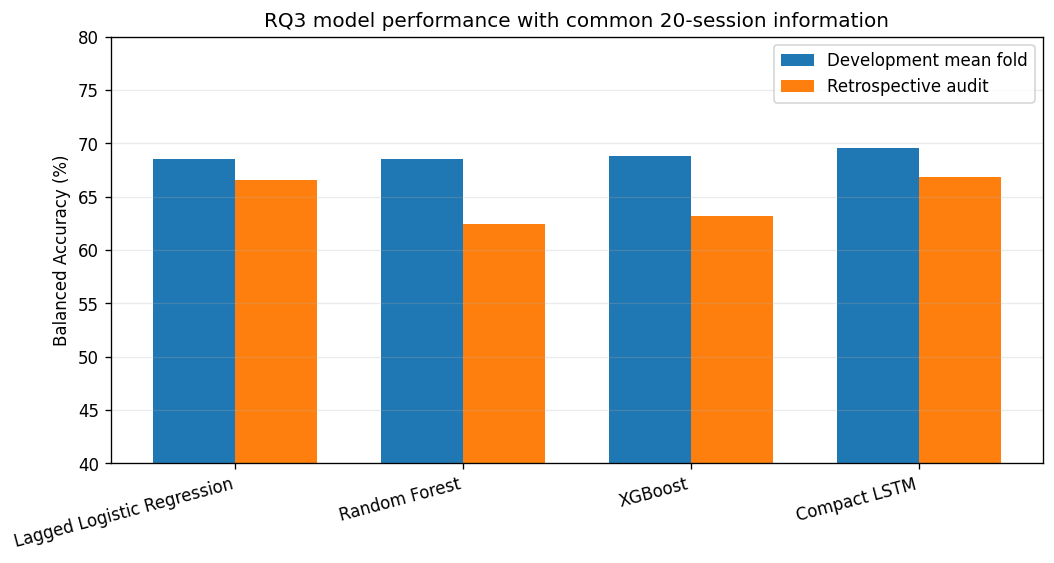

In [5]:
model_summary = summary.loc[summary.Comparator.isin(main_models)].copy()
x = np.arange(len(model_summary)); width = 0.36
fig, ax = plt.subplots(figsize=(9,4.8))
ax.bar(x-width/2, 100*model_summary['Development Mean Fold Balanced Accuracy'], width, label='Development mean fold')
ax.bar(x+width/2, 100*model_summary['Audit Balanced Accuracy'], width, label='Retrospective audit')
ax.set_xticks(x, model_summary.Comparator, rotation=15, ha='right')
ax.set_ylabel('Balanced Accuracy (%)')
ax.set_title('RQ3 model performance with common 20-session information')
ax.set_ylim(40,80); ax.grid(axis='y', alpha=.25); ax.legend()
plt.tight_layout(); plt.show()

In [6]:
primary = bootstrap.loc[bootstrap['Comparison Family'].eq('Primary complex-versus-linear'),
    ['Period','Metric','Comparator A','Comparator B','Point Difference','CI Lower 95%','CI Upper 95%','Holm-adjusted p']]
display(primary.round(4))

,Period,Metric,Comparator A,Comparator B,Point Difference,CI Lower 95%,CI Upper 95%,Holm-adjusted p
0,Development OOF,Accuracy,Random Forest,Lagged Logistic Regression,-0.0048,-0.0400,0.0288,1.0000
1,Development OOF,Accuracy,XGBoost,Lagged Logistic Regression,-0.0008,-0.0312,0.0280,1.0000
2,Development OOF,Accuracy,Compact LSTM,Lagged Logistic Regression,-0.0128,-0.0456,0.0200,1.0000
3,Development OOF,Balanced Accuracy,Random Forest,Lagged Logistic Regression,-0.0061,-0.0409,0.0273,1.0000
4,Development OOF,Balanced Accuracy,XGBoost,Lagged Logistic Regression,-0.0013,-0.0313,0.0267,1.0000
5,Development OOF,Balanced Accuracy,Compact LSTM,Lagged Logistic Regression,-0.0034,-0.0369,0.0279,1.0000
22,Retrospective audit,Accuracy,Random Forest,Lagged Logistic Regression,-0.0418,-0.0811,0.0000,0.1536
23,Retrospective audit,Accuracy,XGBoost,Lagged Logistic Regression,-0.0369,-0.0762,0.0025,0.1536
24,Retrospective audit,Accuracy,Compact LSTM,Lagged Logistic Regression,0.0025,-0.0319,0.0369,0.9454
25,Retrospective audit,Balanced Accuracy,Random Forest,Lagged Logistic Regression,-0.0411,-0.0809,-0.0007,0.1344


In [7]:
phase_main = phases.loc[phases.Comparator.isin(main_models)]
phase_ranges = phase_main.groupby(['Period','Comparator']).agg(
    Min_BA=('Balanced Accuracy','min'), Max_BA=('Balanced Accuracy','max'), SD_BA=('Balanced Accuracy','std')).reset_index()
display(phase_ranges.round(4))

,Period,Comparator,Min_BA,Max_BA,SD_BA
0,Development OOF,Compact LSTM,0.6722,0.7111,0.0150
1,Development OOF,Lagged Logistic Regression,0.6866,0.7001,0.0062
2,Development OOF,Random Forest,0.6456,0.7070,0.0249
3,Development OOF,XGBoost,0.6692,0.7122,0.0179
4,Retrospective audit,Compact LSTM,0.5738,0.7375,0.0687
5,Retrospective audit,Lagged Logistic Regression,0.6105,0.7445,0.0607
6,Retrospective audit,Random Forest,0.5918,0.6631,0.0302
7,Retrospective audit,XGBoost,0.5500,0.6914,0.0636


## Takeaways

1. **Model complexity did not provide statistically conclusive incremental value over lagged LR.** LSTM's audit point estimate was slightly higher, but its paired interval versus LR crossed zero.
2. **The one-SE rule selected Lagged Logistic Regression.** This is a conservative development-only choice, not a claim that LR was uniquely best.
3. **Transparent baselines remain informative.** The selected LR was materially above weekly persistence in the audit, while its advantage over EMA state was not statistically stable across both periods.
4. **RQ4 must use the frozen probabilities and threshold.** It must not reselect the model after seeing economic returns.

## References

Chen, Y., & Yang, Y. (2021). The one standard error rule for model selection: Does it work? *Stats, 4*(4), 868–892. https://doi.org/10.3390/stats4040051

Petrozziello, A., Troiano, L., Serra, A., Jordanov, I., Storti, G., Tagliaferri, R., & La Rocca, M. (2022). Deep learning for volatility forecasting in asset management. *Soft Computing, 26*(17), 8553–8574. https://doi.org/10.1007/s00500-022-07161-1